<a href="https://colab.research.google.com/github/Jellymike/song-popularity-genres/blob/main/Project_Intro_to_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("dataset.csv")
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Displaying basic info
print("Dataset Shape:", df.shape)
print("\nColumn Names & Types:")
print(df.dtypes)

# Checking for missing values
print("\nMissing Values per Column:")
print(df.isnull().sum())

# Checking duplicates (full rows, then same track id)
print("\nFull duplicate rows:", df.duplicated().sum())
print("Duplicate track ids:", df["track_id"].duplicated().sum())

Dataset Shape: (114000, 21)

Column Names & Types:
Unnamed: 0            int64
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object
dtype: object

Missing Values per Column:
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticnes

In [4]:
missing_rows = df[df.isnull().any(axis=1)]
display(missing_rows)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [5]:
# 1. Removing the extra row-number column
df = df.drop(columns=["Unnamed: 0"])

# 2. Removing the row with missing text values
df = df.dropna(subset=['artists', 'album_name', 'track_name'])

# 3. Removing exact duplicates (same song, same genre)
df = df.drop_duplicates()

# 4. Checking how many rows are left
print("After cleaning:", df.shape)

# 5. Making a second table with each song only once (for overall charts)
df_unique = df.drop_duplicates(subset="track_id")
print("Unique songs:", df_unique.shape)

After cleaning: (113549, 20)
Unique songs: (89740, 20)


In [6]:
# Checking if track IDs appear in multiple genres
track_genre_counts = df.groupby('track_id')['track_genre'].nunique()
cross_genre_tracks = track_genre_counts[track_genre_counts > 1]
print(f"Track IDs appearing in more than one genre: {len(cross_genre_tracks)}")

# Checking for exact duplicate rows (same track_id AND same track_genre)
exact_duplicates = exact_duplicates = df.duplicated(subset=['track_id', 'track_genre'], keep=False).sum()
print(f"Exact duplicate rows (same track_id + same genre): {exact_duplicates}")

Track IDs appearing in more than one genre: 16299
Exact duplicate rows (same track_id + same genre): 0


In [7]:
# Check for any remaining missing values in any column
print(df.isnull().sum())

track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [8]:
# Reseting the index of the unique-songs table (0 to 89739
df = df.reset_index(drop=True)

## Exploratory Data Analysis (EDA)

In [9]:
numeric_features = df.select_dtypes(include=['number']).columns.tolist()

print("Numerical features in the dataset:")
print(numeric_features)

Numerical features in the dataset:
['popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


In [10]:
# Core audio features for analysis
audio_features = [
    'danceability', 'energy', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'loudness'
]

In [11]:
# Generating Summary Statistics for Your Audio Features
display(df[audio_features + ['popularity']].describe())

,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo,loudness,popularity
count,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000
mean,0.567031,0.642091,0.084674,0.314064,0.155703,0.213613,0.474205,122.175745,-8.243408,33.324433
std,0.173409,0.251053,0.105762,0.331906,0.309217,0.190462,0.259204,29.972954,5.011422,22.283855
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-49.531000,0.000000
25%,0.456000,0.473000,0.035900,0.016800,0.000000,0.098000,0.260000,99.296000,-9.998000,17.000000
50%,0.580000,0.685000,0.048900,0.168000,0.000041,0.132000,0.464000,122.020000,-6.997000,35.000000
75%,0.695000,0.854000,0.084500,0.596000,0.048700,0.273000,0.683000,140.074000,-5.001000,50.000000
max,0.985000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,4.532000,100.000000


* Popularity: the average is 33 and the median is 33, so it’s fairly balanced. Half of all songs fall between 19 and 49, and only a few reach the top (max 100). The minimum is 0, but the 25% value is 19, so zeros are probably a small group. Let’s confirm with a count below.
* Danceability, energy, valence: the mean and median are close together, so these are fairly evenly spread. Energy leans a bit high (median 0.68).
* Speechiness: the median is 0.049 but the max is 0.965. Most songs have very little spoken word, and a small group (rap, podcasts, comedy) is very high.
* Acousticness: the mean (0.33) is well above the median (0.19), so most songs are low, with a long tail of very acoustic songs.
* Instrumentalness: the median is 0.000058, essentially zero. Most songs have vocals, and a minority are fully instrumental. This feature is very skewed, so it may be less useful on its own.
* Liveness: the mean (0.22) is above the median (0.13), so most songs sound studio-recorded, and a few sound live.
* Tempo: the mean and median are both about 122 beats per minute. But the minimum is 0, which isn’t a real tempo. That’s likely a data error.
* Loudness: the median is -7.2 dB and the minimum is -49.5, so a few very quiet songs pull the average down. The max of 4.5 is a little above 0 dB, which can happen in Spotify’s loudness measure, so that’s not necessarily an error.

In [12]:
print("Songs with tempo 0:", (df_unique["tempo"] == 0).sum())
print("Songs with popularity 0:", (df_unique["popularity"] == 0).sum())
df = df[df["tempo"] > 0]

# Removing songs with tempo of 0
df = df[df["tempo"] > 0]

# Rebuilding the unique-songs table
df_unique = df.drop_duplicates(subset="track_id")

Songs with tempo 0: 157
Songs with popularity 0: 9447


## Popularity Distribution Histogram

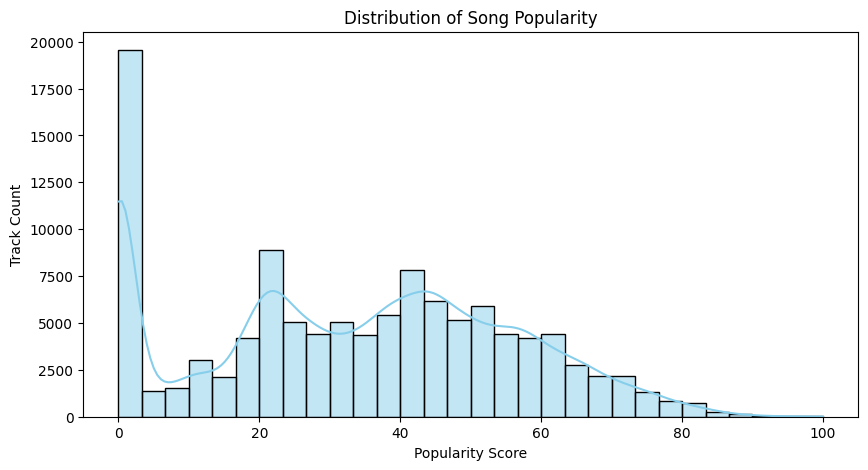

count    89583.000000
mean        33.191800
std         20.592792
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64


In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(df['popularity'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity Score')
plt.ylabel('Track Count')
plt.show()
print(df_unique["popularity"].describe())

Popularity is not normally distributed. There is a spike near 0 (about 10.5% of songs have a score of exactly 0), two broad groups of songs centered around 20 and 45, and few songs above 80. The mean popularity is 33 and the median is 33. Because typical popularity may differ by genre, we plan to define popular songs relative to each genre.

## Feature Distributions (Continuous Audio Features + Duration)

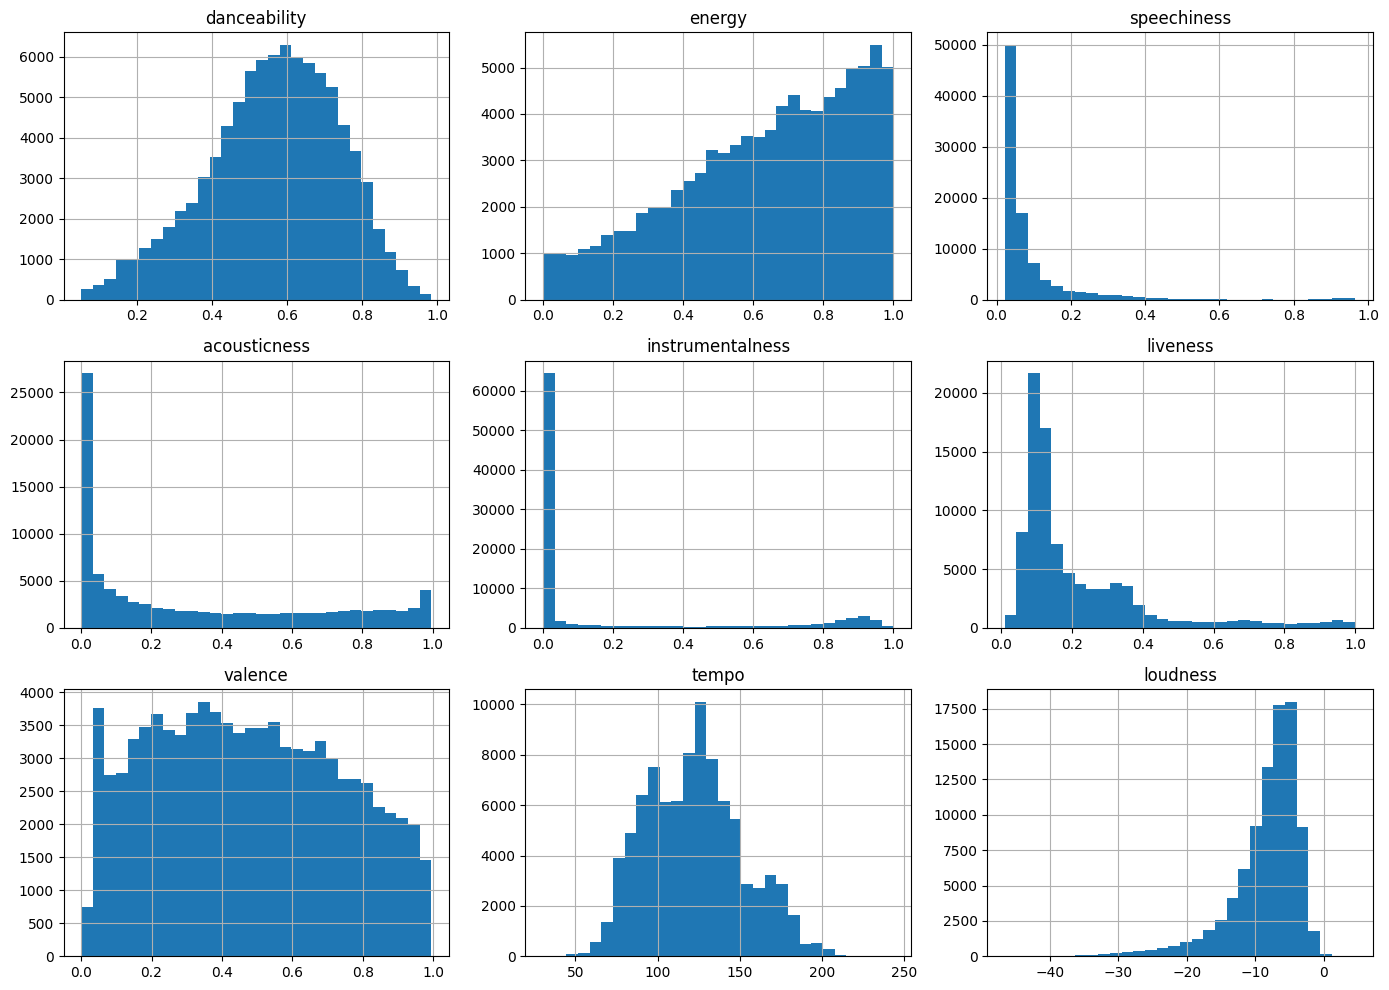

In [14]:
df_unique[audio_features].hist(bins=30, figsize=(14, 10))

plt.tight_layout()

plt.show()

Danceability and tempo are roughly bell-shaped, while energy is skewed toward high values. Speechiness, acousticness, instrumentalness, and liveness are concentrated near 0, with a smaller group of songs at high values. Valence is spread out fairly evenly from 0.05 to 0.8, with fewer very happy songs. No single typical value. Loudness is skewed toward quieter outliers.

## Comprehensive Correlation Heatmap

popularity          1.000000
loudness            0.073262
danceability        0.065965
energy              0.014449
tempo               0.008790
valence            -0.010934
liveness           -0.014269
acousticness       -0.038991
speechiness        -0.046861
instrumentalness   -0.128516
Name: popularity, dtype: float64


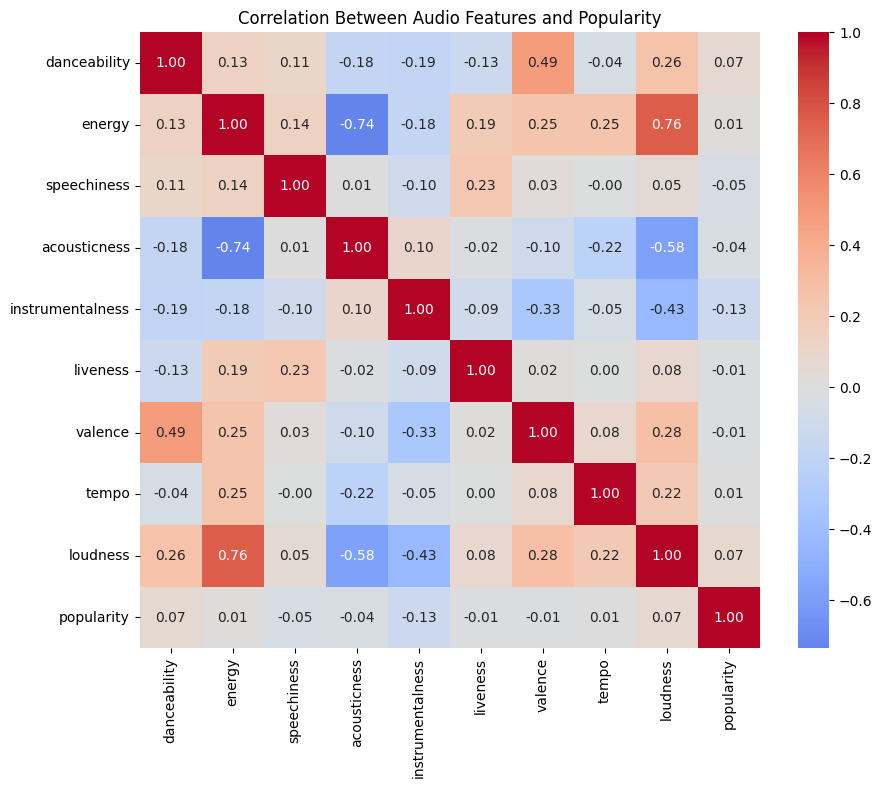

In [ ]:
# Choosing the columns to compare
cols = audio_features + ["popularity"]

# Calculating the correlation between every pair
corr = df_unique[cols].corr()

# Showing how each feature relates to popularity
print(corr["popularity"].sort_values(ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Audio Features and Popularity")
plt.show()

Features vs. each other (the rest of the grid)

* Energy and loudness (0.76): high-energy songs are louder.
* Energy and acousticness (-0.74): acoustic songs are lower in energy.
* Acousticness and loudness (-0.58): acoustic songs are quieter.
* Danceability and valence (0.49): danceable songs tend to sound happier.
* Instrumentalness and loudness (-0.43): instrumental songs are quieter.

This means some features carry overlapping information. It will matter later if you build a model, since energy, loudness, and acousticness partly say the same thing.

Across all songs, correlations between audio features and popularity are weak (all below 0.15 in absolute value). The strongest are instrumentalness (-0.13), loudness (0.07), and danceability (0.07). Energy, loudness, and acousticness are strongly related to each other. This suggests no single feature explains popularity overall, which motivates analyzing genres separately.

## Boxplot of per-genre correlations for each feature
Selection deleted



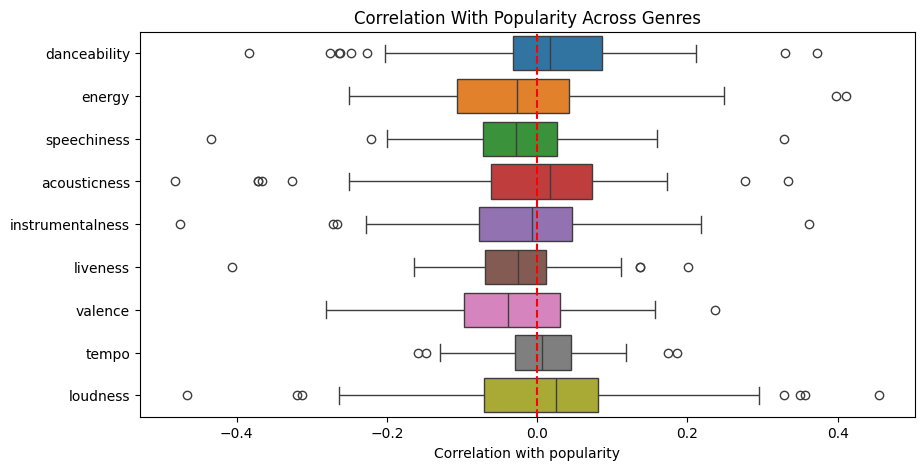

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=genre_corr, orient="h")


plt.axvline(0, color="red", linestyle="--")
plt.title("Correlation With Popularity Across Genres")
plt.xlabel("Correlation with popularity")
plt.show()

In [ ]:
# Correlation of each feature with popularity, inside each genre
genre_corr = df.groupby("track_genre")[audio_features + ["popularity"]].corr()["popularity"].unstack()

# Removing the popularity-with-itself column
genre_corr = genre_corr.drop(columns="popularity")

# See how much the correlations vary across genres (min, average, max)
print(genre_corr.describe().loc[["min", "mean", "max"]].round(2))

# Genres where danceability matters most and least
print(genre_corr["danceability"].sort_values().head(5))
print(genre_corr["danceability"].sort_values().tail(5))

      danceability  energy  speechiness  acousticness  instrumentalness  \
min          -0.38   -0.25        -0.43         -0.48             -0.48   
mean          0.02   -0.02        -0.02         -0.01             -0.01   
max           0.37    0.41         0.33          0.33              0.36   

      liveness  valence  tempo  loudness  
min      -0.41    -0.28  -0.16     -0.47  
mean     -0.02    -0.04   0.00      0.01  
max       0.20     0.24   0.19      0.46  
track_genre
sleep       -0.382848
hip-hop     -0.275869
iranian     -0.263600
pagode      -0.262188
breakbeat   -0.247853
Name: danceability, dtype: float64
track_genre
world-music    0.187194
garage         0.204159
classical      0.211682
funk           0.329847
comedy         0.373015
Name: danceability, dtype: float64
